# The USD / EUR exchange rate



In [1]:
# import relevant packages
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Problem 1

Download historical exchange rate data for the DKK/USD currency pair using Yahoo Finance. Use '2006-01-01' as start date. 

In [2]:
# hent DKK/USD valutakurs siden 2006
dkk_usd_data = yf.download('DKKUSD=X', start='2006-01-01')

# kig på de første rækker
dkk_usd_data.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,DKKUSD=X,DKKUSD=X,DKKUSD=X,DKKUSD=X,DKKUSD=X
Date,,,,,
2006-01-02,0.158336,0.158897,0.158479,0.158607,0
2006-01-03,0.161267,0.159360,0.159109,0.159284,0
2006-01-04,0.162356,0.162425,0.161645,0.161715,0
2006-01-05,0.162290,0.162198,0.161993,0.162198,0
2006-01-06,0.162798,0.163100,0.162030,0.162077,0


**Tolkning:** We downloaded daily DKK/USD exchange rate data from Yahoo Finance, starting from 2006. Each row shows the price on a given day - meaning how many US dollars one Danish krone was worth that day.

## Problem 2

Define two `pd.Series` with the DKK / USD and USD / DKK exchange rate using the closing price. 

In [3]:
# DKK/USD (hvor mange dollars er 1 krone værd)
dkk_usd = dkk_usd_data['Close']['DKKUSD=X']

# USD/DKK (den omvendte kurs - hvor mange kroner er 1 dollar værd)
usd_dkk = 1 / dkk_usd

# kig på de første par værdier af begge
print(dkk_usd.head())
print(usd_dkk.head())

Date
2006-01-02    0.158336
2006-01-03    0.161267
2006-01-04    0.162356
2006-01-05    0.162290
2006-01-06    0.162798
Name: DKKUSD=X, dtype: float64
Date
2006-01-02    6.3157
2006-01-03    6.2009
2006-01-04    6.1593
2006-01-05    6.1618
2006-01-06    6.1426
Name: DKKUSD=X, dtype: float64


**Tolkning:** We extracted just the closing price as two separate series: DKK/USD (dollars per krone) and its inverse, USD/DKK (kroner per dollar). Taking 1 divided by the exchange rate is the standard way to flip a currency pair around.

## Problem 3

Plot the time series of the exchanges rates and the natural logarithm of the exhanges rates in two seperate figures. 

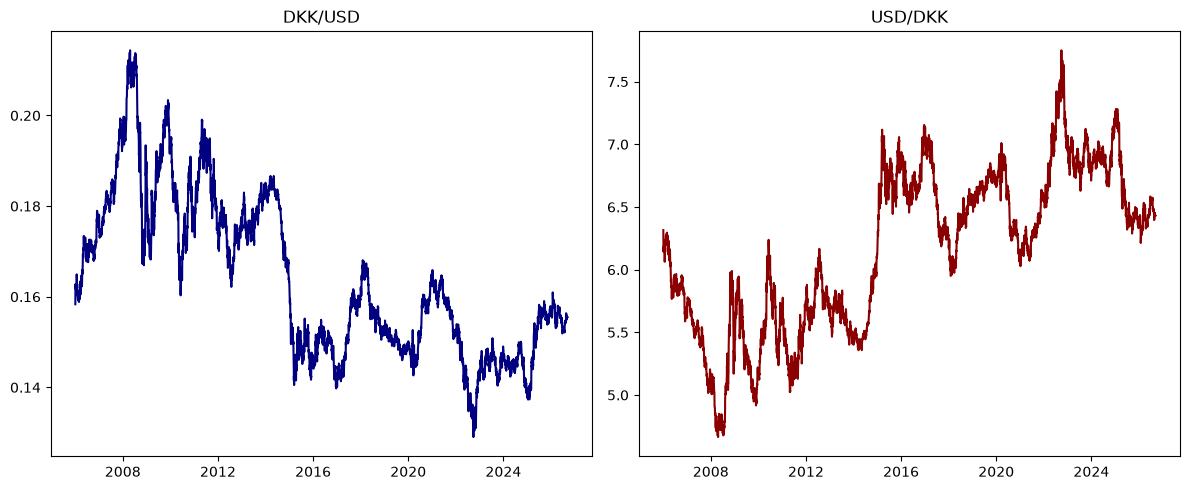

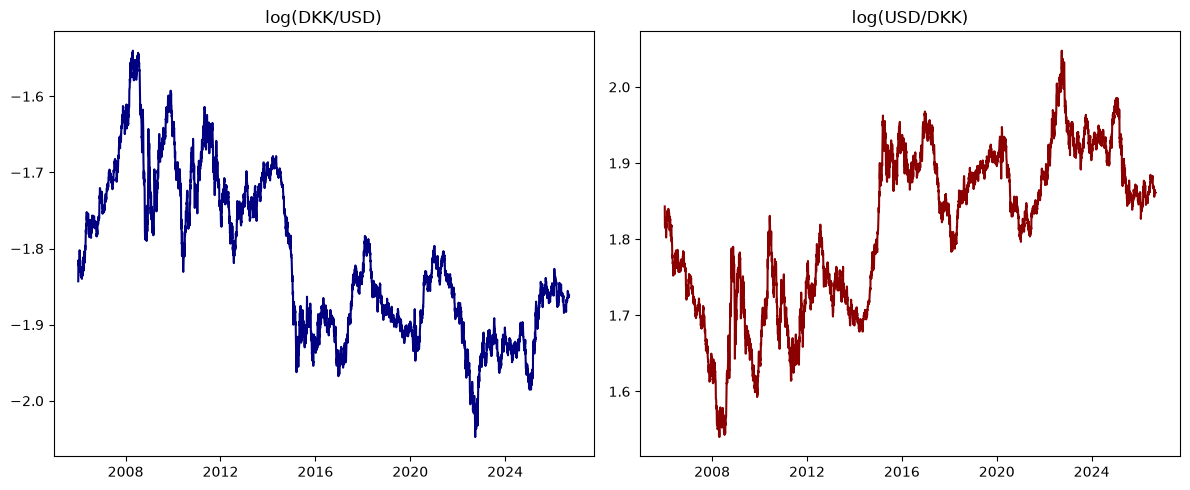

In [4]:
# Figur 1: de rå valutakurser
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(dkk_usd, color="navy")
axes[0].set_title("DKK/USD")

axes[1].plot(usd_dkk, color="darkred")
axes[1].set_title("USD/DKK")

plt.tight_layout()
plt.show()

# Figur 2: de log-transformerede valutakurser
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(np.log(dkk_usd), color="navy")
axes[0].set_title("log(DKK/USD)")

axes[1].plot(np.log(usd_dkk), color="darkred")
axes[1].set_title("log(USD/DKK)")

plt.tight_layout()
plt.show()

**Tolkning:** The raw exchange rate plots (DKK/USD and USD/DKK) look like mirror images of each other. After taking the logarithm, the two plots become nearly identical in shape, just flipped upside down - this is because log(1/x) = -log(x). This illustrates why log-transformed prices are often easier to work with statistically than raw prices.

## Problem 4

Plot the density of the weekly changes in the natural logarithm of DKK / USD for both the first and second half of the sample. Use either a histogram from the `matplotlib` package or `seaborn.kdeplot`. 


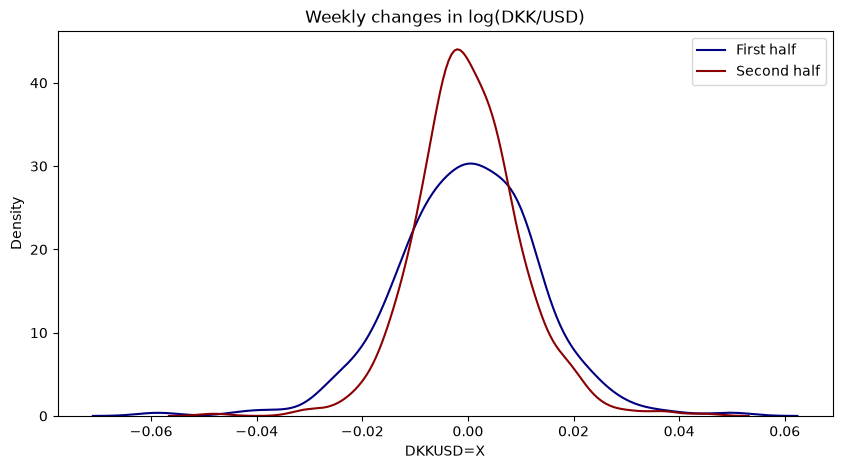

In [9]:
import seaborn as sns
# log-transformér og omsampl til ugentlig frekvens (tag fredagens værdi hver uge)
log_dkk_usd = np.log(dkk_usd)
log_dkk_usd_weekly = log_dkk_usd.resample('W').last()

# beregn ugentlige ændringer (differencen fra uge til uge)
weekly_changes = log_dkk_usd_weekly.diff().dropna()

# split i to halvdele
half_point = int(len(weekly_changes) / 2)
first_half = weekly_changes.iloc[:half_point]
second_half = weekly_changes.iloc[half_point:]

# plot begge densiteter
fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(first_half, color="navy", label="First half", ax=ax)
sns.kdeplot(second_half, color="darkred", label="Second half", ax=ax)
ax.set_title("Weekly changes in log(DKK/USD)")
ax.legend()
plt.show()


**Tolkning:** The density plots for both halves are centered close to zero, but the second half (red) is noticeably taller and narrower than the first half (blue) - meaning the second half had lower volatility (smaller weekly swings) than the first half. This suggests the "invariant" assumption doesn't hold perfectly here: while the average change is stable over time (centering is similar), the spread of the changes is not fully constant, hinting at time-varying volatility (similar to the volatility clustering concept from lecture 2).

## Problem 5

Plot a scatter plot between the weekly changes in the natural logarithm of DKK / USD and its lagged value. 

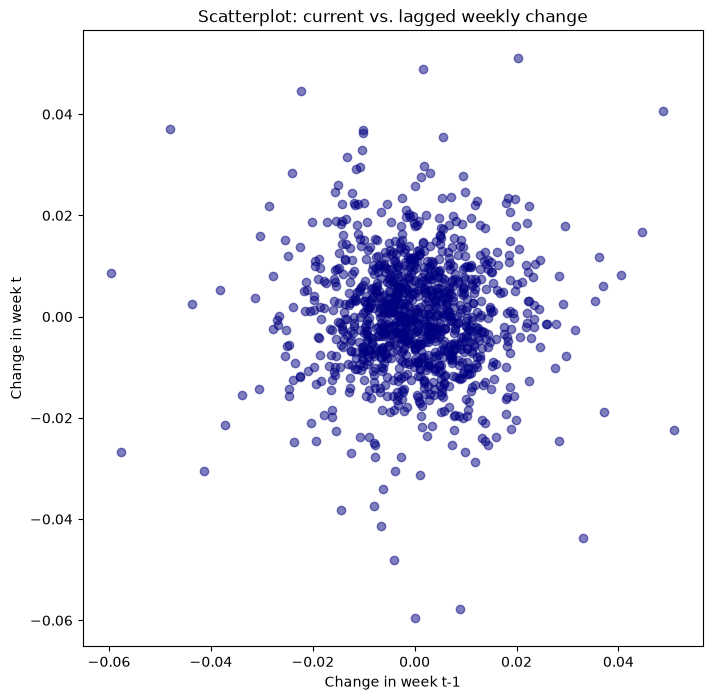

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))
pd.plotting.lag_plot(weekly_changes, alpha=0.5, ax=ax, c="navy")
ax.set_xlabel("Change in week t-1")
ax.set_ylabel("Change in week t")
ax.set_title("Scatterplot: current vs. lagged weekly change")
plt.show()

**Tolkning:** The scatterplot shows a shapeless, cloud-like pattern with no visible trend or structure between this week's change and last week's change. This is the informal "lag plot" test for independence from lecture 2 - the absence of a pattern supports the idea that weekly log-changes behave independently from one period to the next.

## Problem 6

Plot the autocorrelation function for the weekly changes in the natural logarithm of DKK / USD.


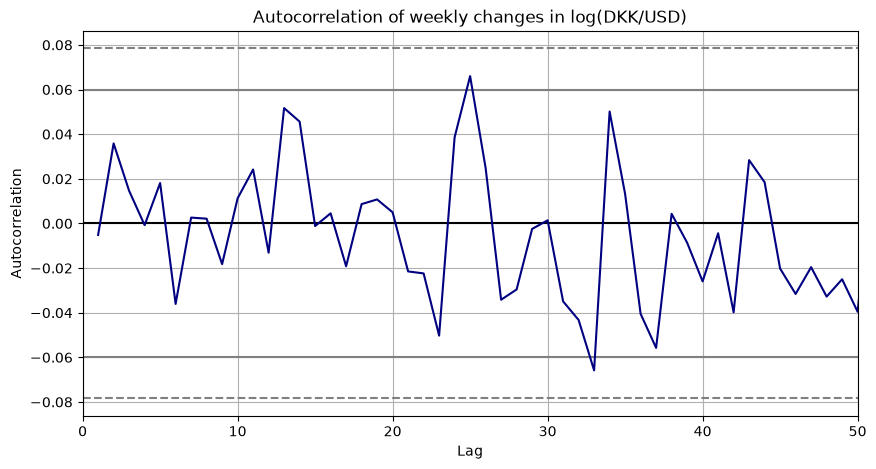

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
pd.plotting.autocorrelation_plot(weekly_changes, ax=ax, color="navy")
ax.set_xlim([0, 50])
ax.set_title("Autocorrelation of weekly changes in log(DKK/USD)")
plt.show()

**Tolkning:** The autocorrelation plot stays close to zero at nearly all lags, mostly within the dashed confidence bands. This is the third and most systematic of the informal invariant tests from lecture 2 (after the split-histogram and lag-plot tests), and it checks correlation at every lag at once rather than just one at a time. Combined with the previous two tests, this strongly supports treating weekly log-changes in the exchange rate as i.i.d. invariants.